# Frente de ML – variante: prever os próximos H minutos

**Pergunta:** treinar o Random Forest de 1 min para prever o retorno dos **próximos H minutos** (e não só do próximo minuto), segurando a posição por H minutos, dá lucro depois dos custos?

Hipótese registrada **antes** de treinar, em `resultados/ml/hipotese_horizonte.json`:

| Item | Definição |
|---|---|
| Modelo | Mesmo do oficial (`rf_d4_f2`), features `COMPLETO`, 1 min, janela 12 meses, re-treino trimestral |
| Alvo | Retorno (%) do fechamento de *t* ao fechamento de *t+H*, dentro do pregão; H ∈ {10, 20} min |
| Embargo | H candles entre treino e previsão |
| Regra | Entra se \|previsão\| > limiar e segura **exatamente H minutos**; sem sobreposição de operações |
| Limiar | Quantis 0/50/75/90% de \|previsão\| na validação 2024 |
| Escolha | Na validação: maior esperança com t ≥ 2 entre as 8 combinações H × limiar |
| Custo | 5 pts por operação (sensibilidade 0 e 10) |

In [1]:
import os, sys, json, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

sys.path.append(PASTA)
import tt1_comum as t

SAIDA = f"{PASTA}/resultados/ml"
CFG = json.load(open(f"{SAIDA}/config_final.json", encoding="utf-8"))
HIP = json.load(open(f"{SAIDA}/hipotese_horizonte.json", encoding="utf-8"))
FEATS = t.features()["COMPLETO"]
CANDLE, JANELA = CFG["candle"], CFG["janela_meses"]
HS = HIP["horizontes_H_min"]
QUANTIS = [0.0, 0.5, 0.75, 0.9]
PERIODOS = {"validacao_2024": t.VALIDACAO, "teste_2025_03-2026": t.TESTE, "novo_04-09-2026": ("2026-04-01", "2026-09-26")}

class FolhaProporcional:
    # mesmo modelo de frente_ml.ipynb: min_samples_leaf = max(10, folha_frac × nº de linhas do treino)
    def __init__(self, estimador, folha_frac=0.01, folha_min=10):
        self.estimador, self.folha_frac, self.folha_min = estimador, folha_frac, folha_min
    def fit(self, X, y):
        self.min_leaf_ = max(self.folha_min, int(self.folha_frac * len(X)))
        self.m = clone(self.estimador).set_params(min_samples_leaf=self.min_leaf_).fit(X, y)
        return self
    def predict(self, X):
        return self.m.predict(X)

assert CFG["modelo"] == "rf_d4_f2"
FABRICA = lambda: FolhaProporcional(RandomForestRegressor(n_estimators=CFG["n_arvores"], max_depth=4, max_features=0.5,
                                                          n_jobs=-1, random_state=42), folha_frac=0.02)

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
BASE = {"comum": t.montar_base(win, wdo, CANDLE)[0],     # validação e teste (base do projeto, até 01/04/2026)
        "win": t.montar_base(win, win, CANDLE)[0]}       # período novo (só WIN; colunas *_wdo não entram nas features)

## Alvo de H minutos

`close_fut` = fechamento H candles à frente **no mesmo pregão**. Linhas sem H candles até o fim do pregão ficam sem alvo (não treinam e não operam).

In [2]:
def com_alvo_h(df, H):
    dia = pd.Series(df.index.date, index=df.index)
    d = df.copy()
    d["close_fut"] = d.groupby(dia)["close"].shift(-H)
    d["alvo"] = np.log(d["close_fut"] / d["close"]) * 100
    return d.dropna(subset=["alvo"])

def clark_west(y, f, lags):
    adj = y ** 2 - ((y - f) ** 2 - f ** 2)
    d, n = adj - adj.mean(), len(adj)
    s2 = d @ d / n + sum(2 * (1 - l / (lags + 1)) * (d[l:] @ d[:-l]) / n for l in range(1, lags + 1))
    return adj.mean() / np.sqrt(s2 / n)

PREV = {}
for H in HS:
    for periodo, (ini, fim) in PERIODOS.items():
        base = com_alvo_h(BASE["win" if periodo.startswith("novo") else "comum"], H)
        p = t.walk_forward(base, FEATS, FABRICA, ini, fim, janela_meses=JANELA, embargo=H)
        p["close_fut"] = base.loc[p.index, "close_fut"]
        p.to_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_rf_h{H}_{periodo}.csv")
        PREV[(H, periodo)] = p
        m = t.metricas(p)
        print(f"H={H:>2} {periodo:<20} {len(p):>7,} linhas | Theil U {m['TheilU']:.4f} | R²_oos {m['R2_oos']:.4f} | "
              f"acurácia {m['acc_dir']:.3f} | Clark-West t {clark_west(p.y_true.values, p.y_pred.values, H + 5):.2f}")

H=10 validacao_2024       138,706 linhas | Theil U 1.0006 | R²_oos -0.0013 | acurácia 0.506 | Clark-West t -0.16


H=10 teste_2025_03-2026   171,469 linhas | Theil U 1.0005 | R²_oos -0.0010 | acurácia 0.506 | Clark-West t -0.10


H=10 novo_04-09-2026       67,715 linhas | Theil U 1.0004 | R²_oos -0.0009 | acurácia 0.492 | Clark-West t -0.38


H=20 validacao_2024       136,196 linhas | Theil U 1.0015 | R²_oos -0.0030 | acurácia 0.509 | Clark-West t -0.25


H=20 teste_2025_03-2026   168,359 linhas | Theil U 1.0008 | R²_oos -0.0016 | acurácia 0.506 | Clark-West t 0.21


H=20 novo_04-09-2026       66,485 linhas | Theil U 1.0008 | R²_oos -0.0016 | acurácia 0.492 | Clark-West t -0.36


## Simulação: horizonte fixo, sem sobreposição

In [3]:
def operacoes_horizonte(prev, H, limiar, custo_pts):
    # entra no fechamento de t se |previsão| > limiar; sai no fechamento de t+H; só entra sem posição aberta
    yp, c, cf = prev.y_pred.values, prev.close.values, prev.close_fut.values
    idx, ops, i, n = prev.index, [], 0, len(prev)
    while i < n:
        if abs(yp[i]) > limiar:
            lado = 1 if yp[i] > 0 else -1
            ops.append((idx[i], lado, lado * (cf[i] - c[i])))
            saida = idx[i] + pd.Timedelta(minutes=H)
            i = idx.searchsorted(saida)          # próxima decisão a partir do candle de saída
        else:
            i += 1
    ops = pd.DataFrame(ops, columns=["inicio", "lado", "bruto"])
    ops["pontos"] = ops.bruto - custo_pts
    return ops

def resumo(ops):
    x = ops.pontos
    g, p = x[x > 0], x[x < 0]
    ep = x.std() / np.sqrt(len(x))
    return dict(n_ops=len(x), ops_por_dia=len(x) / ops.inicio.dt.date.nunique(), taxa_acerto=(x > 0).mean(),
                payoff=g.mean() / -p.mean(), esperanca_pts=x.mean(), ep_pts=ep, t_stat=x.mean() / ep,
                fator_lucro=g.sum() / -p.sum(), resultado_R=x.sum() * t.PONTO_WIN)

def aleatorio(ops, custo_pts, seed=42):
    rng = np.random.default_rng(seed)
    return ops.assign(pontos=ops.bruto * rng.choice([-1, 1], size=len(ops)) - custo_pts)

LIM = {(H, q): t.limiar_por_quantil(PREV[(H, "validacao_2024")], q) for H in HS for q in QUANTIS}
linhas, OPS = [], {}
for (H, periodo), prev in PREV.items():
    for q in QUANTIS:
        for custo in t.CUSTOS_PTS:
            ops = operacoes_horizonte(prev, H, LIM[(H, q)], custo)
            if custo == 5:
                OPS[(H, periodo, q)] = ops
            linhas.append(dict(H=H, periodo=periodo, limiar_q=q, serie="modelo", custo_pts=custo, **resumo(ops)))
            linhas.append(dict(H=H, periodo=periodo, limiar_q=q, serie="aleatorio", custo_pts=custo,
                               **resumo(aleatorio(ops, custo))))
res = pd.DataFrame(linhas)
res.to_csv(f"{SAIDA}/horizonte_resultados.csv", index=False)

## Escolha na validação 2024 (custo 5 pts)

In [4]:
v = res[(res.periodo == "validacao_2024") & (res.serie == "modelo") & (res.custo_pts == 5)]
display(v[["H", "limiar_q", "n_ops", "ops_por_dia", "taxa_acerto", "payoff", "esperanca_pts", "ep_pts", "t_stat",
           "fator_lucro", "resultado_R"]].round(3))
ok = v[(v.esperanca_pts > 0) & (v.t_stat >= 2)]
ESCOLHA = tuple(ok.sort_values("esperanca_pts", ascending=False).iloc[0][["H", "limiar_q"]]) if len(ok) else None
print("Escolha:", f"H = {int(ESCOLHA[0])} min, limiar {ESCOLHA[1]:.0%}" if ESCOLHA else
      "nenhuma combinação com t ≥ 2 → sem evidência; os testes ficam só como sensibilidade")

,H,limiar_q,n_ops,ops_por_dia,taxa_acerto,payoff,esperanca_pts,ep_pts,t_stat,fator_lucro,resultado_R
2,10,0.00,14024,55.873,0.476,0.962,-4.211,1.115,-3.778,0.913,-11811.0
8,10,0.50,9299,37.048,0.482,0.943,-4.161,1.477,-2.817,0.919,-7739.0
14,10,0.75,5353,21.327,0.475,0.960,-5.463,1.994,-2.740,0.900,-5849.0
20,10,0.90,2600,10.833,0.457,0.964,-10.388,3.251,-3.196,0.838,-5402.0
74,20,0.00,7010,27.928,0.479,0.938,-7.757,2.248,-3.451,0.888,-10876.0
80,20,0.50,4567,18.195,0.482,0.963,-5.108,2.817,-1.814,0.925,-4666.0
86,20,0.75,2328,9.387,0.481,0.949,-6.791,4.212,-1.612,0.909,-3162.0
92,20,0.90,898,4.317,0.469,1.002,-8.235,8.175,-1.007,0.908,-1479.0


Escolha: nenhuma combinação com t ≥ 2 → sem evidência; os testes ficam só como sensibilidade


## Resultados nos três períodos (custo 5 pts)

In [5]:
tab = res[(res.custo_pts == 5)].pivot_table(index=["H", "limiar_q"], columns=["periodo", "serie"],
                                             values="esperanca_pts").round(2)
display(tab)
tt = res[(res.custo_pts == 5) & (res.serie == "modelo")].pivot_table(index=["H", "limiar_q"], columns="periodo",
                                                                       values="t_stat").round(2)
print("t da esperança (modelo, custo 5 pts):"); display(tt)
br = res[(res.custo_pts == 0) & (res.serie == "modelo")].pivot_table(index=["H", "limiar_q"], columns="periodo",
                                                                       values="esperanca_pts").round(2)
print("Ganho por operação ANTES do custo (pts):"); display(br)

periodo     novo_04-09-2026        teste_2025_03-2026        validacao_2024  \
serie             aleatorio modelo          aleatorio modelo      aleatorio   
H  limiar_q                                                                   
10 0.00               -4.25  -6.90              -7.30  -4.23          -4.93   
   0.50               -5.60 -10.95              -4.90  -3.37          -6.52   
   0.75               -5.26 -13.67              -5.08  -4.89          -4.81   
   0.90               -3.48  -7.71              -2.37  -6.27           0.55   
20 0.00              -13.75 -13.27              -4.09  -3.54          -3.72   
   0.50               -7.57 -13.60             -15.00  -4.24          -5.34   
   0.75               -6.77 -12.25               0.53  -8.31          -4.59   
   0.90              -24.04  -7.46              -7.20  -6.24         -11.52   

periodo             
serie       modelo  
H  limiar_q         
10 0.00      -4.21  
   0.50      -4.16  
   0.75      -5.46  
   0.90     -10.39  
20 0.00      -7.76  
   0.50      -5.11  
   0.75      -6.79  
   0.90      -8.23

t da esperança (modelo, custo 5 pts):


periodo      novo_04-09-2026  teste_2025_03-2026  validacao_2024
H  limiar_q                                                     
10 0.00                -2.32               -2.87           -3.78
   0.50                -2.51               -1.30           -2.82
   0.75                -2.47               -1.38           -2.74
   0.90                -1.05               -1.53           -3.20
20 0.00                -2.17               -1.20           -3.45
   0.50                -1.47               -0.80           -1.81
   0.75                -0.97               -1.29           -1.61
   0.90                -0.37               -0.72           -1.01

Ganho por operação ANTES do custo (pts):


periodo      novo_04-09-2026  teste_2025_03-2026  validacao_2024
H  limiar_q                                                     
10 0.00                -1.90                0.77            0.79
   0.50                -5.95                1.63            0.84
   0.75                -8.67                0.11           -0.46
   0.90                -2.71               -1.27           -5.39
20 0.00                -8.27                1.46           -2.76
   0.50                -8.60                0.76           -0.11
   0.75                -7.25               -3.31           -1.79
   0.90                -2.46               -1.24           -3.23

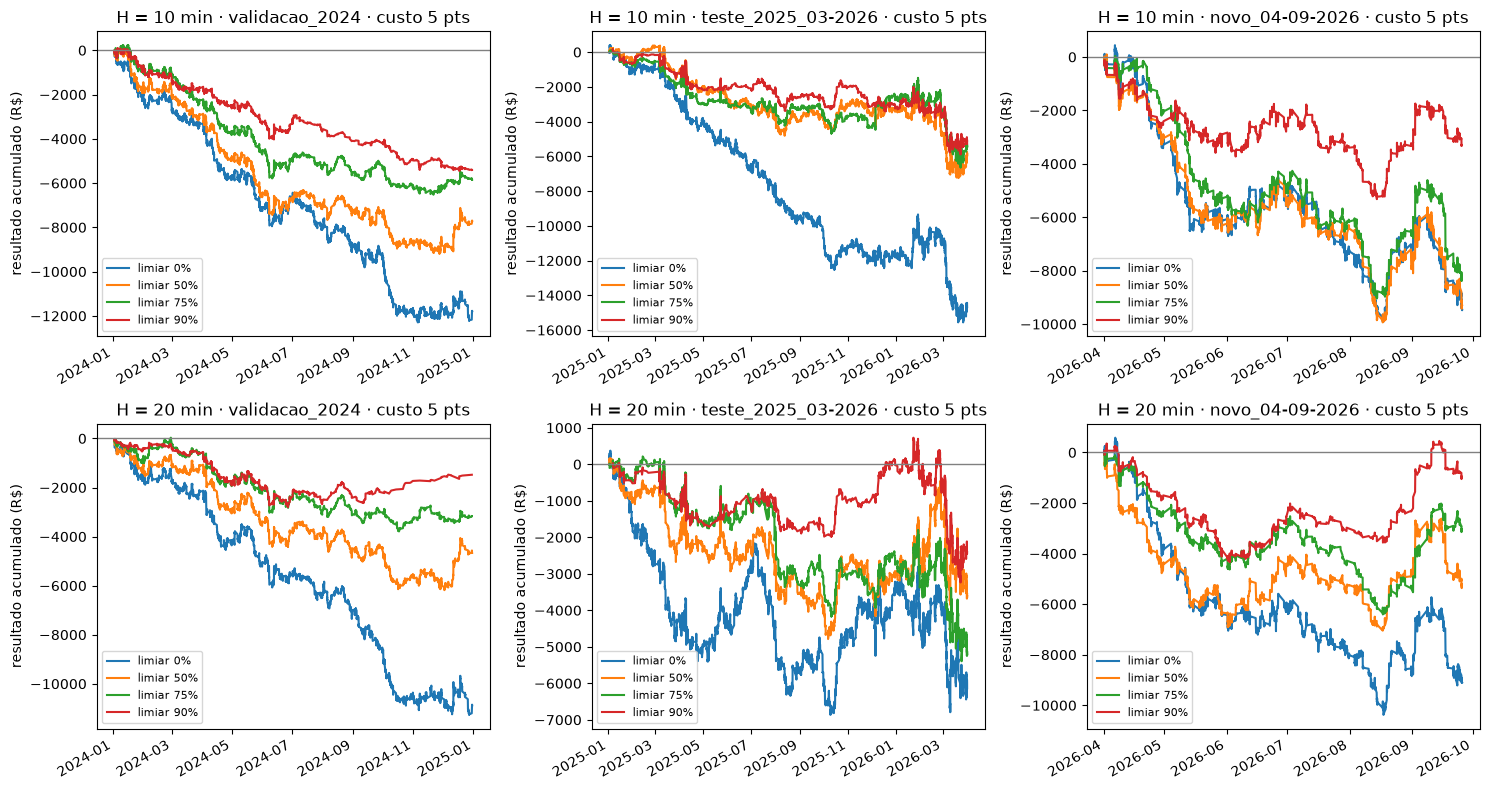

In [6]:
fig, axes = plt.subplots(len(HS), 3, figsize=(15, 4 * len(HS)), squeeze=False)
for i, H in enumerate(HS):
    for j, periodo in enumerate(PERIODOS):
        ax = axes[i, j]
        for q in QUANTIS:
            o = OPS[(H, periodo, q)]
            (o.set_index("inicio").pontos.cumsum() * t.PONTO_WIN).plot(ax=ax, label=f"limiar {q:.0%}")
        ax.axhline(0, color="gray", lw=1)
        ax.set_title(f"H = {H} min · {periodo} · custo 5 pts"); ax.set_xlabel("")
        ax.set_ylabel("resultado acumulado (R$)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f"{SAIDA}/horizonte_curvas.png", dpi=150); plt.show()

## Sensibilidade secundária: segurar até virar o sinal (não entra na escolha)

Mesmas previsões de H minutos, com a regra da variante anterior: mantém a posição até a previsão passar o limiar do lado oposto; zera no fim do dia.

In [7]:
def operacoes_segurando(prev, limiar, custo_pts):
    yp, dia = prev.y_pred.values, prev.index.date
    pos, p = np.zeros(len(prev)), 0
    for i in range(len(prev)):
        if i == 0 or dia[i] != dia[i - 1]:
            p = 0
        if yp[i] > limiar:
            p = 1
        elif yp[i] < -limiar:
            p = -1
        pos[i] = p
    dia_s = pd.Series(prev.index.date, index=prev.index)
    mov = prev.close_prox.values - prev.close.values
    nova = (pos != np.roll(pos, 1)) | (dia_s != dia_s.shift()).values
    nova[0] = True
    d = pd.DataFrame({"op": np.cumsum(nova), "lado": pos, "pts": pos * mov, "inicio": prev.index})
    d = d[d.lado != 0]
    ops = d.groupby("op").agg(lado=("lado", "first"), bruto=("pts", "sum"), inicio=("inicio", "first"))
    ops["pontos"] = ops.bruto - custo_pts
    return ops

sens = []
for (H, periodo), prev in PREV.items():
    for q in QUANTIS:
        sens.append(dict(H=H, periodo=periodo, limiar_q=q, **resumo(operacoes_segurando(prev, LIM[(H, q)], 5))))
sens = pd.DataFrame(sens)
sens.to_csv(f"{SAIDA}/horizonte_segurar_sensibilidade.csv", index=False)
display(sens.pivot_table(index=["H", "limiar_q"], columns="periodo", values=["esperanca_pts", "t_stat"]).round(2))

esperanca_pts                                            t_stat  \
periodo     novo_04-09-2026 teste_2025_03-2026 validacao_2024 novo_04-09-2026   
H  limiar_q                                                                     
10 0.00               -6.09              -2.75          -3.92           -3.23   
   0.50              -10.03               5.76          -4.71           -0.78   
   0.75              -77.38               3.10         -12.19           -1.47   
   0.90             -160.24             -69.67         -17.14           -1.60   
20 0.00               -6.02              -1.90          -6.73           -2.22   
   0.50              -64.07              -9.26         -42.85           -1.28   
   0.75              -94.45             -64.46         -24.16           -0.96   
   0.90              -59.97             -53.79         -52.81           -0.49   

                                               
periodo     teste_2025_03-2026 validacao_2024  
H  limiar_q                                    
10 0.00                  -2.04          -1.89  
   0.50                   0.40          -0.23  
   0.75                   0.09          -0.32  
   0.90                  -1.54          -0.36  
20 0.00                  -0.86          -1.47  
   0.50                  -0.28          -1.52  
   0.75                  -1.44          -0.61  
   0.90                  -0.97          -1.04